# Enron email corpus — exploratory analysis

Works on the corpus built by `jevron ingest` from the CMU release (`enron_mail_20150507.tar.gz`):

- `data/emails.parquet`: one row per distinct email (255,170), with `n_copies` and `mailboxes`
- `data/locations.parquet`: one row per original message file (517,401), giving its mailbox and folder

Parsing, encoding handling and deduplication live in `jevron.corpus`, which this notebook shares
with the CLI and the browser. If the files are missing, the first cell builds them (about 1–2 minutes).

In [1]:
from collections import Counter
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

from jevron import corpus

pd.set_option("display.max_colwidth", 80)

TARBALL = corpus.DEFAULT_TARBALL      # ~/Downloads/enron_mail_20150507.tar.gz
DATA_DIR = Path("data")

## 1. Load the corpus

In [2]:
if not (corpus.emails_path(DATA_DIR).exists() and corpus.locations_path(DATA_DIR).exists()):
    print(f"Building the corpus from {TARBALL} (same as `jevron ingest`) ...")
    corpus.build(TARBALL, DATA_DIR)

emails = corpus.load(DATA_DIR)
locations = corpus.load_locations(DATA_DIR)
emails["n_recipients"] = emails["to"].str.len() + emails["cc"].str.len() + emails["bcc"].str.len()
emails["body_len"] = emails["body"].str.len()
print(f"{len(emails):,} distinct emails from {len(locations):,} files in {locations['user'].nunique()} mailboxes")
emails.head()

255,170 distinct emails from 517,401 files in 150 mailboxes


,message_id,date,from,to,cc,bcc,subject,x_from,user,folder,body,path,n_copies,mailboxes,n_recipients,body_len
0,<32467700.1075846198563.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,steven.kean@enron.com,[],[],[],california energy prices,Steven J Kean,kean-s,all_documents,Summary of what we discussed the other night:\n\nBackground:\n\n\npower -- p...,data/raw/maildir/kean-s/all_documents/2141.,4,[kean-s],0,1365
1,<33385514.1075854437036.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,kay.chapman@enron.com,"[tim.belden@enron.com, kevin.presto@enron.com, john.arnold@enron.com, scott....","[patti.thompson@enron.com, mollie.gustafson@enron.com, felicia.doan@enron.co...","[patti.thompson@enron.com, mollie.gustafson@enron.com, felicia.doan@enron.co...",ENA Management Committee,Kay Chapman,delainey-d,all_documents,"\n The Friday September 1, 2000 ENA Management Committee Meeting has been \...",data/raw/maildir/delainey-d/all_documents/362.,2,[delainey-d],61,2193
2,<25323182.1075854432336.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,kay.chapman@enron.com,"[david.w.delainey@enron.com, lavorato@enron.com, tim.belden@enron.com, derek...","[kay.chapman@enron.com, kimberly.hillis@enron.com, angela.mcculloch@enron.co...","[kay.chapman@enron.com, kimberly.hillis@enron.com, angela.mcculloch@enron.co...",2000 ENA Vegas Offsite,Kay Chapman,delainey-d,all_documents,Attached please find the invitation for the Las Vegas Offsite to be held at ...,data/raw/maildir/delainey-d/all_documents/160.,2,[delainey-d],121,265
3,<11039522.1075848306657.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,david.delainey@enron.com,[kay.chapman@enron.com],[],[],ENA 2000 Offsite,David W Delainey,delainey-d,all_documents,Given tremendous energy market volatility and as we stretch resources to mak...,data/raw/maildir/delainey-d/all_documents/1.,2,[delainey-d],1,304
4,<13564084.1075846659497.JavaMail.evans@thyme>,1980-01-01 00:00:00+00:00,susan.scott@enron.com,[],[],[],,Susan Scott,scott-s,all_documents,Koch Gateway has a provision in the Negotiated Rates section of its tariff \...,data/raw/maildir/scott-s/all_documents/123.,2,[scott-s],0,1090


## 2. Duplicates

The same message often appears in several folders (`sent`, `sent_items`, `_sent_mail`, `all_documents`, …) and in several users' mailboxes.
`jevron ingest` deduplicates on (sender, date, subject, body) and records how many files held each email.

In [3]:
print(f"{len(locations):,} files -> {len(emails):,} distinct emails ({1 - len(emails) / len(locations):.0%} duplicates)")
emails["n_copies"].value_counts().sort_index().head(10).rename("emails").to_frame().T

517,401 files -> 255,170 distinct emails (51% duplicates)


n_copies,1,2,3,4,5,6,7,8,9,10
emails,124193,62413,39129,20721,3034,2688,738,523,654,159


## 3. Volume over time

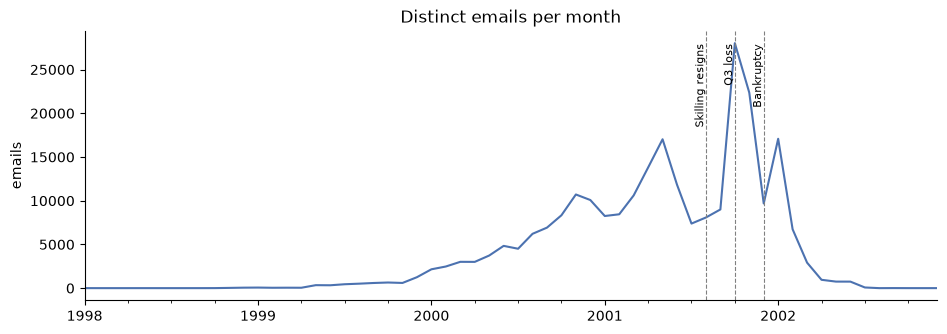

In [4]:
# A handful of messages carry bogus dates (1979, 2044, ...); keep the real window.
emails = emails[(emails["date"] >= "1998-01-01") & (emails["date"] < "2003-01-01")]

monthly = emails.set_index("date").resample("MS").size()
ax = monthly.plot(figsize=(11, 3.5), color="#4C72B0")
ax.set(title="Distinct emails per month", xlabel="", ylabel="emails")
for d, label in [("2001-08-14", "Skilling resigns"), ("2001-10-16", "Q3 loss"), ("2001-12-02", "Bankruptcy")]:
    ax.axvline(pd.Timestamp(d, tz="UTC"), color="gray", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d, tz="UTC"), ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", ha="right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

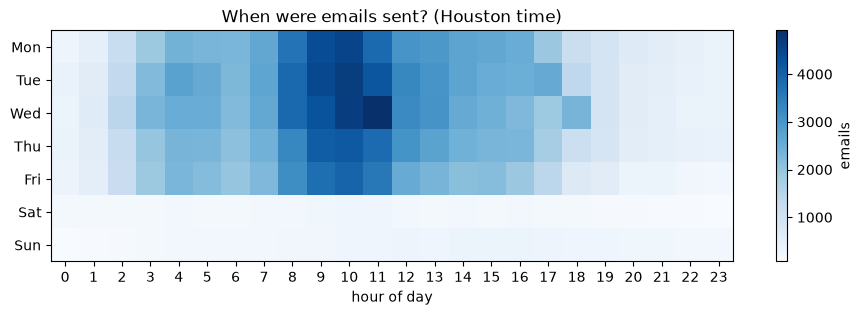

In [5]:
local = emails["date"].dt.tz_convert("US/Central")  # Enron HQ was in Houston
heat = pd.crosstab(local.dt.day_of_week, local.dt.hour).reindex(index=range(7), columns=range(24), fill_value=0)
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_yticks(range(7)); ax.set_yticklabels(heat.index)
ax.set(title="When were emails sent? (Houston time)", xlabel="hour of day")
fig.colorbar(im, ax=ax, label="emails")
plt.show()

## 4. Who sends and receives the most

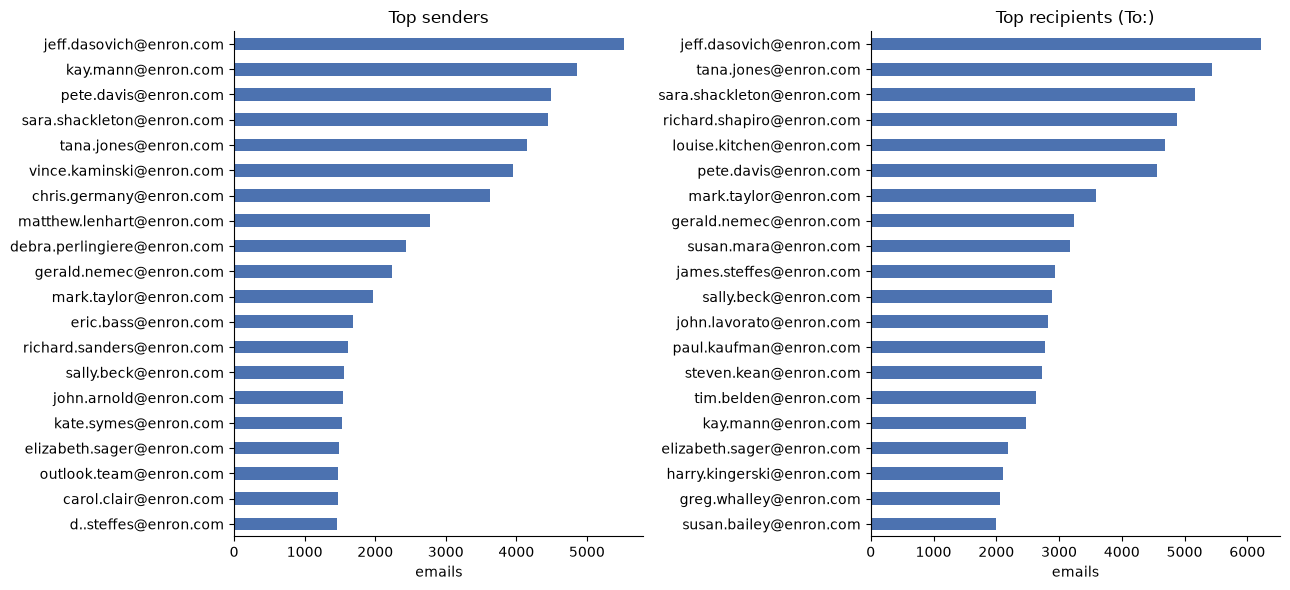

In [6]:
top_senders = emails["from"].value_counts().head(20)
top_recipients = emails.explode("to")["to"].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, s, title in [(axes[0], top_senders, "Top senders"), (axes[1], top_recipients, "Top recipients (To:)")]:
    s.sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=title, xlabel="emails", ylabel="")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
is_internal = lambda a: isinstance(a, str) and a.endswith("@enron.com")
print(f"Sent from @enron.com: {emails['from'].map(is_internal).mean():.1%}")
domains = emails["from"].dropna().str.split("@").str[-1].value_counts().head(15)
domains

Sent from @enron.com: 77.8%


from
enron.com                      198118
aol.com                          1773
hotmail.com                      1690
mailman.enron.com                1258
yahoo.com                         970
ccomad3.uu.commissioner.com       783
nymex.com                         776
haas.berkeley.edu                 734
txu.com                           683
caiso.com                         548
carrfut.com                       522
concureworkplace.com              521
nyiso.com                         514
williams.com                      475
earthlink.net                     448
Name: count, dtype: int64

## 5. Mailboxes and folders

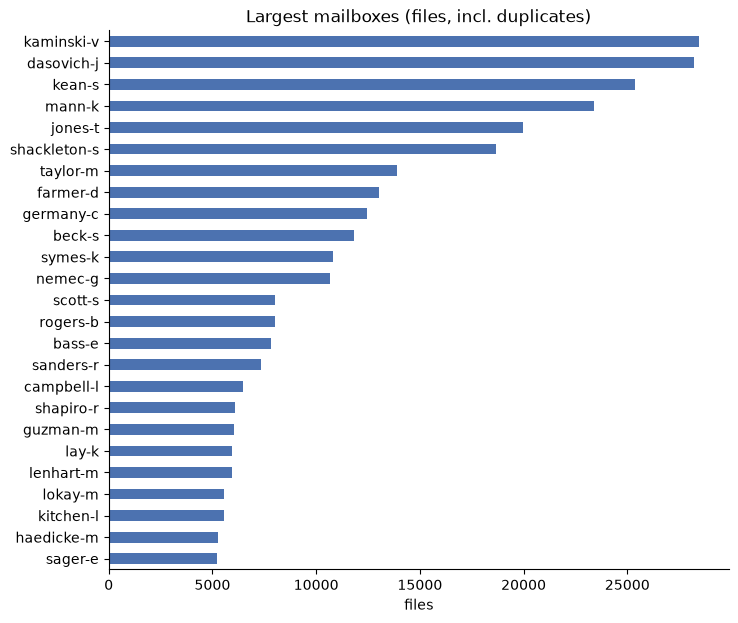

folder
all_documents          128103
discussion_threads      58609
sent                    57653
deleted_items           51356
inbox                   44859
sent_items              37921
notes_inbox             36665
_sent_mail              30109
calendar                 6133
archiving                4477
_americas                4021
personal                 2577
attachments              2026
meetings                 1872
c                        1656
schedule_crawler         1398
chris_stokley            1252
logistics                1192
archive                  1179
tw_commercial_group      1159
Name: count, dtype: int64

In [8]:
per_user = locations.groupby("user").size().sort_values(ascending=False)
ax = per_user.head(25).sort_values().plot.barh(figsize=(8, 7), color="#4C72B0")
ax.set(title="Largest mailboxes (files, incl. duplicates)", xlabel="files", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

locations["folder"].str.split("/").str[0].value_counts().head(20)

## 6. Communication network (who emails whom)

In [9]:
edges = (
    emails.explode("to")
    .dropna(subset=["from", "to"])
    .query("`from` != to")
    .groupby(["from", "to"]).size()
    .rename("n").sort_values(ascending=False)
    .reset_index()
)
print(f"{len(edges):,} distinct sender->recipient pairs")
edges.head(25)

308,577 distinct sender->recipient pairs


,from,to,n
0,vince.kaminski@enron.com,vkaminski@aol.com,1141
1,jeff.dasovich@enron.com,susan.mara@enron.com,934
2,jeff.dasovich@enron.com,paul.kaufman@enron.com,877
3,jeff.dasovich@enron.com,richard.shapiro@enron.com,863
4,jeff.dasovich@enron.com,james.steffes@enron.com,780
5,jeff.dasovich@enron.com,karen.denne@enron.com,724
6,jeff.dasovich@enron.com,harry.kingerski@enron.com,546
7,jeff.dasovich@enron.com,skean@enron.com,528
8,jeff.dasovich@enron.com,sandra.mccubbin@enron.com,499
9,michelle.nelson@enron.com,mike.maggi@enron.com,494


## 7. Message content

count     254687.0
mean        1864.0
std         8905.0
min            1.0
25%          283.0
50%          766.0
75%         1765.0
max      2011422.0
Name: body_len, dtype: float64


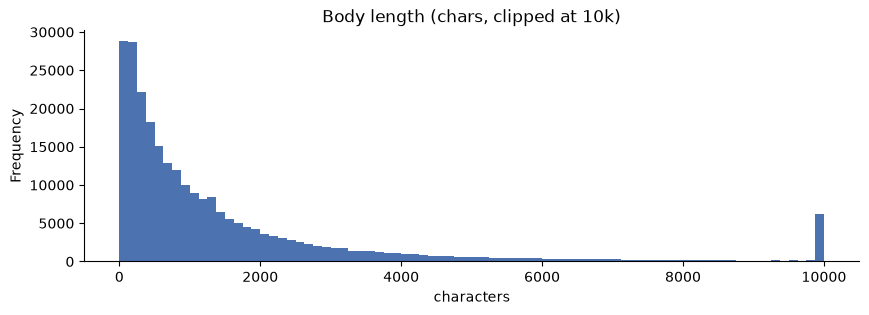

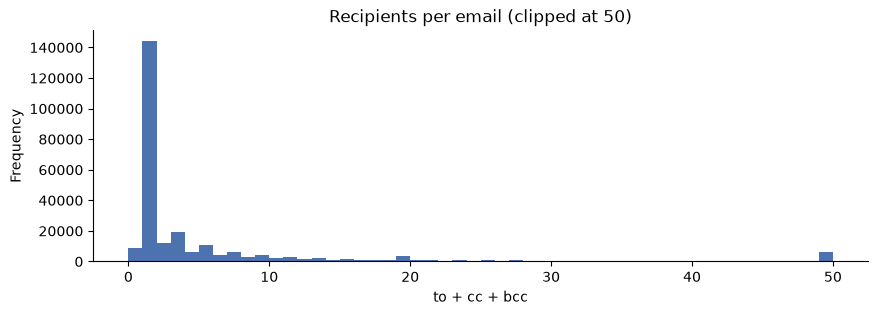

In [10]:
print(emails["body_len"].describe().round(0))
ax = emails["body_len"].clip(upper=10_000).plot.hist(bins=80, figsize=(10, 3), color="#4C72B0")
ax.set(title="Body length (chars, clipped at 10k)", xlabel="characters")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

ax = emails["n_recipients"].clip(upper=50).plot.hist(bins=50, figsize=(10, 3), color="#4C72B0")
ax.set(title="Recipients per email (clipped at 50)", xlabel="to + cc + bcc")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [11]:
STOP = set("""re fw fwd the a an and or of to for in on at is with from by your you our we this that
it be are as - & : / meeting update""".split())
words = Counter(
    w for s in emails["subject"].str.lower()
    for w in re.findall(r"[a-z][a-z']+", s) if w not in STOP and len(w) > 2
)
pd.Series(dict(words.most_common(30))).to_frame("count").T

,enron,gas,new,agreement,energy,power,com,report,request,hourahead,...,trading,access,draft,daily,revised,news,list,california,market,day
count,10799,5895,5848,5243,5099,4988,4875,4646,4517,4417,...,2470,2452,2437,2360,2274,2254,2247,2245,2191,1979


In [12]:
def search(term, n=10):
    """Case-insensitive search over subject + body (same matching as `jevron emails --search`)."""
    hits = corpus.filter_emails(emails, search=term)
    print(f"{len(hits):,} emails mention {term!r}")
    return hits[["date", "from", "subject"]].sort_values("date").head(n)

search("raptor")

409 emails mention 'raptor'


,date,from,subject
14123,2000-04-12 16:22:00+00:00,paulo.issler@enron.com,Talon
16331,2000-05-02 18:33:00+00:00,carol.clair@enron.com,Project Raptor
16332,2000-05-02 18:38:00+00:00,carol.clair@enron.com,Project Raptor
17377,2000-05-11 13:37:00+00:00,david.delainey@enron.com,Re: Raptor
17387,2000-05-11 14:32:00+00:00,david.delainey@enron.com,Re: Raptor
17410,2000-05-11 15:44:00+00:00,david.delainey@enron.com,Re: Raptor
19657,2000-05-31 11:24:00+00:00,eric.bass@enron.com,Re: ESPN.com - College Basketball - Draft: Mihm stands tall at No.\n 1
20810,2000-06-08 10:00:00+00:00,carol.clair@enron.com,Raptor Dinner
21940,2000-06-15 15:21:00+00:00,carol.clair@enron.com,Raptor 2
22483,2000-06-20 11:09:00+00:00,carol.clair@enron.com,raptor II
